# 03 · Supervised challenger — gradient boosting, significance and explanations

**Question:** does a higher-capacity tree ensemble beat the logistic baseline by more than the fold noise, and what
does it rely on?

Reproduce:
```
python -m satelliteguard.models.tune hgb
python -m satelliteguard.models.train
python -m satelliteguard.evaluation.compare hgb logreg
python -m satelliteguard.models.explain
python -m satelliteguard.evaluation.plots
```
Same protocol as notebook 02: train split only, 15 episode-grouped folds, frozen test untouched.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from satelliteguard import load_config

cfg = load_config()
P, FIG = cfg["paths"], cfg["paths"]["figures"]
M = json.loads(P["metrics"].read_text())["cv"]
C = json.loads((P["metrics"].parent / "comparisons.json").read_text())
show = lambda name: display(Image(filename=str(FIG / f"{name}.png")))

## 1. Bounded tuning with the one-standard-error rule

In [2]:
grid = pd.read_csv(P["metrics"].parent / "tuning" / "hgb_grid.csv")
grid[["max_leaf_nodes", "learning_rate", "pr_auc_mean", "pr_auc_std", "one_se_choice"]]

,max_leaf_nodes,learning_rate,pr_auc_mean,pr_auc_std,one_se_choice
0,16,0.10,0.9298,0.0532,False
1,31,0.10,0.9296,0.0516,False
2,8,0.10,0.9287,0.0521,False
3,16,0.03,0.9262,0.0571,False
4,31,0.03,0.9261,0.0545,False
5,4,0.10,0.9251,0.0561,False
6,8,0.03,0.9246,0.0625,False
7,4,0.03,0.9188,0.0599,True


8 configurations (leaves per tree × learning rate; 300 trees, `min_samples_leaf=20`, L2 = 1). The best scores 0.930,
but everything is within noise of everything else. The one-SE rule picks the **simplest** configuration within one
standard error: **4 leaves per tree, learning rate 0.03** (0.919).

Early stopping is deliberately **off**: sklearn's early stopping holds out a *random* internal validation split, which
would put neighbouring segments on both sides — the Day 1 leakage again, one level down.

## 2. Head-to-head

In [3]:
cols = ["prevalence", "channel_only", "logreg", "hgb"]
pd.DataFrame({n: {
    "PR-AUC": f"{M[n]['cv_folds']['pr_auc_mean']:.3f} ± {M[n]['cv_folds']['pr_auc_std']:.3f}",
    "ROC-AUC": M[n]["cv_folds"]["roc_auc_mean"],
    "precision@policy": M[n]["cv_oof_at_threshold"]["precision"],
    "recall@policy": M[n]["cv_oof_at_threshold"]["recall"],
    "MCC": M[n]["cv_oof_at_threshold"]["mcc"],
    "recall@top25%": M[n]["cv_oof_at_threshold"]["recall_at_top25pct"],
    "Brier": M[n]["cv_oof_at_threshold"].get("brier"),
} for n in cols}).T

,PR-AUC,ROC-AUC,precision@policy,recall@policy,MCC,recall@top25%,Brier
prevalence,0.201 ± 0.002,0.5,0.2032,0.9844,0.0289,0.2866,0.1608
channel_only,0.250 ± 0.050,0.4853,0.2181,1.0,0.1446,0.2181,0.1723
logreg,0.878 ± 0.078,0.9446,0.827,0.8193,0.7788,0.891,0.0598
hgb,0.919 ± 0.060,0.9605,0.8154,0.8255,0.7748,0.8816,0.0516


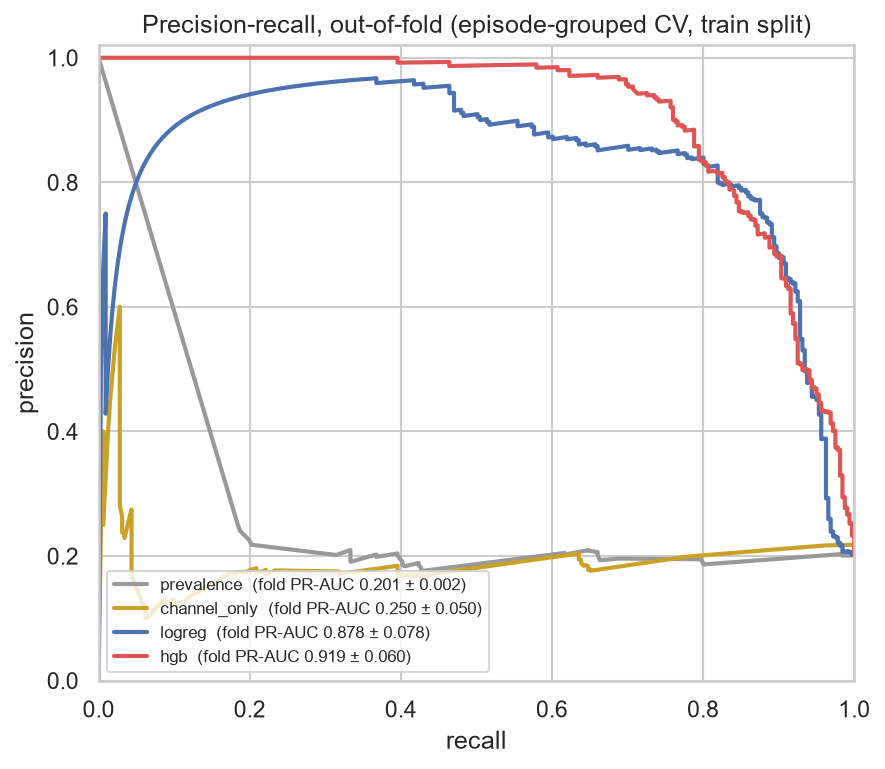

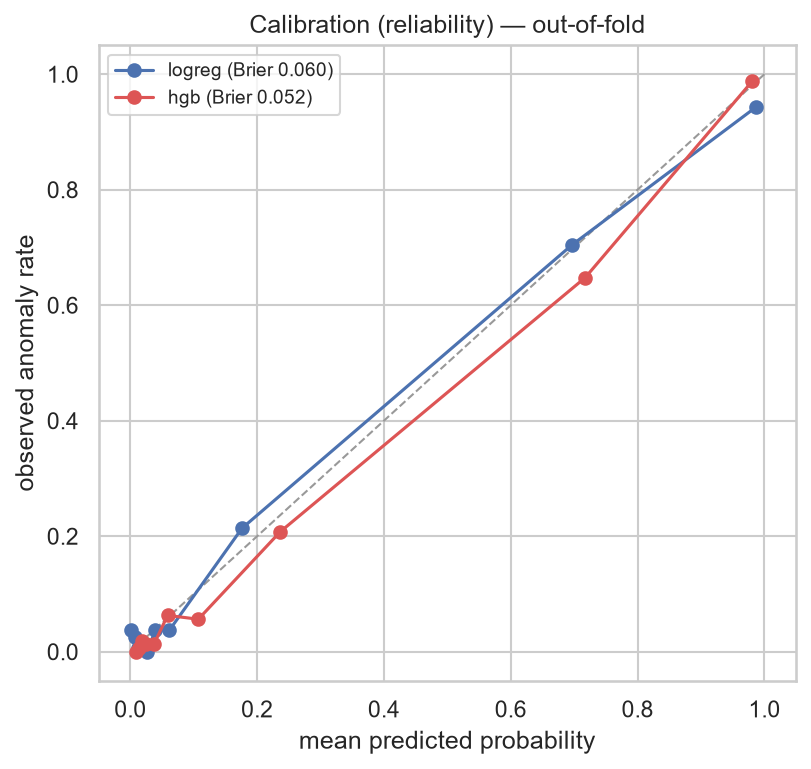

In [4]:
show("18_cv_pr_logreg_vs_hgb"); show("19_cv_calibration_logreg_vs_hgb")

Gradient boosting has the higher PR-AUC (0.919 vs 0.878), lower fold variance, and better calibration
(Brier 0.052 vs 0.060). **At the review threshold, however, both models perform almost identically** (precision ≈ 0.82,
recall ≈ 0.82): the boosting gain is in the *ordering at the extremes* (the PR curve sits higher at low and high recall),
not at the operating point.

## 3. Is the difference real? A corrected paired test

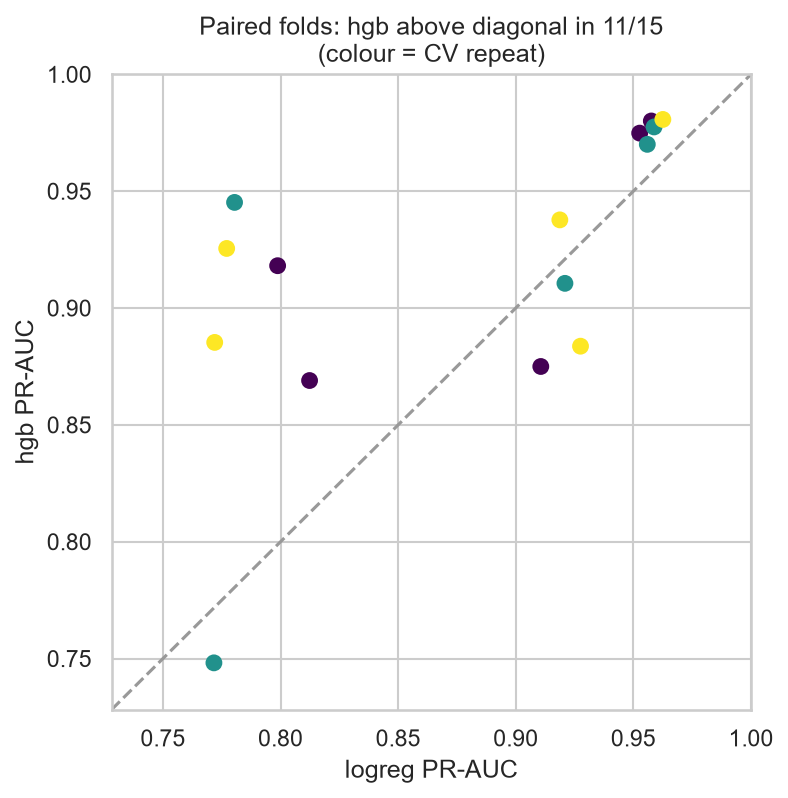

,a,b,metric,mean_diff,sd_diff,folds_a_better,n_folds,t_naive,p_naive,t_corrected,p_corrected
hgb_vs_logreg_pr_auc,hgb,logreg,pr_auc,0.0402,0.0661,11,15,2.356,0.0336,1.081,0.298
hgb_vs_logreg_roc_auc,hgb,logreg,roc_auc,0.0159,0.0342,10,15,1.797,0.0939,0.825,0.4234


In [5]:
show("20_cv_paired_folds")
pd.DataFrame({k: v for k, v in C.items() if k.startswith("hgb_vs_logreg")}).T

Both models were evaluated on **identical folds**, so we compare them fold by fold. Boosting wins 11 of 15 folds
(+0.040 PR-AUC on average).

- A **naive paired t-test** says p = 0.034 → "significant".
- But repeated k-fold scores are **not independent**: training sets overlap ~75% between folds and fully across repeats.
  The **Nadeau–Bengio corrected t-test** inflates the variance by (1/J + n_test/n_train) instead of 1/J, giving
  **p = 0.30 → not significant**.

**Conclusion:** the evidence favours boosting but does not establish a significant improvement on 1,594 segments.

**Decision:** gradient boosting becomes the **primary** supervised model (better point estimate, lower variance,
better calibration, wins most folds, enables exact SHAP explanations). Logistic regression stays as the
**interpretable baseline**. Both are scored on the frozen test once, and the report states that the CV difference
is not statistically significant.

## 4. What the model uses — SHAP on held-out segments

Each segment is explained by the fold model that **did not train on it**, so these are out-of-sample explanations.
SHAP values are additive in log-odds: base value + Σ SHAP = model output.

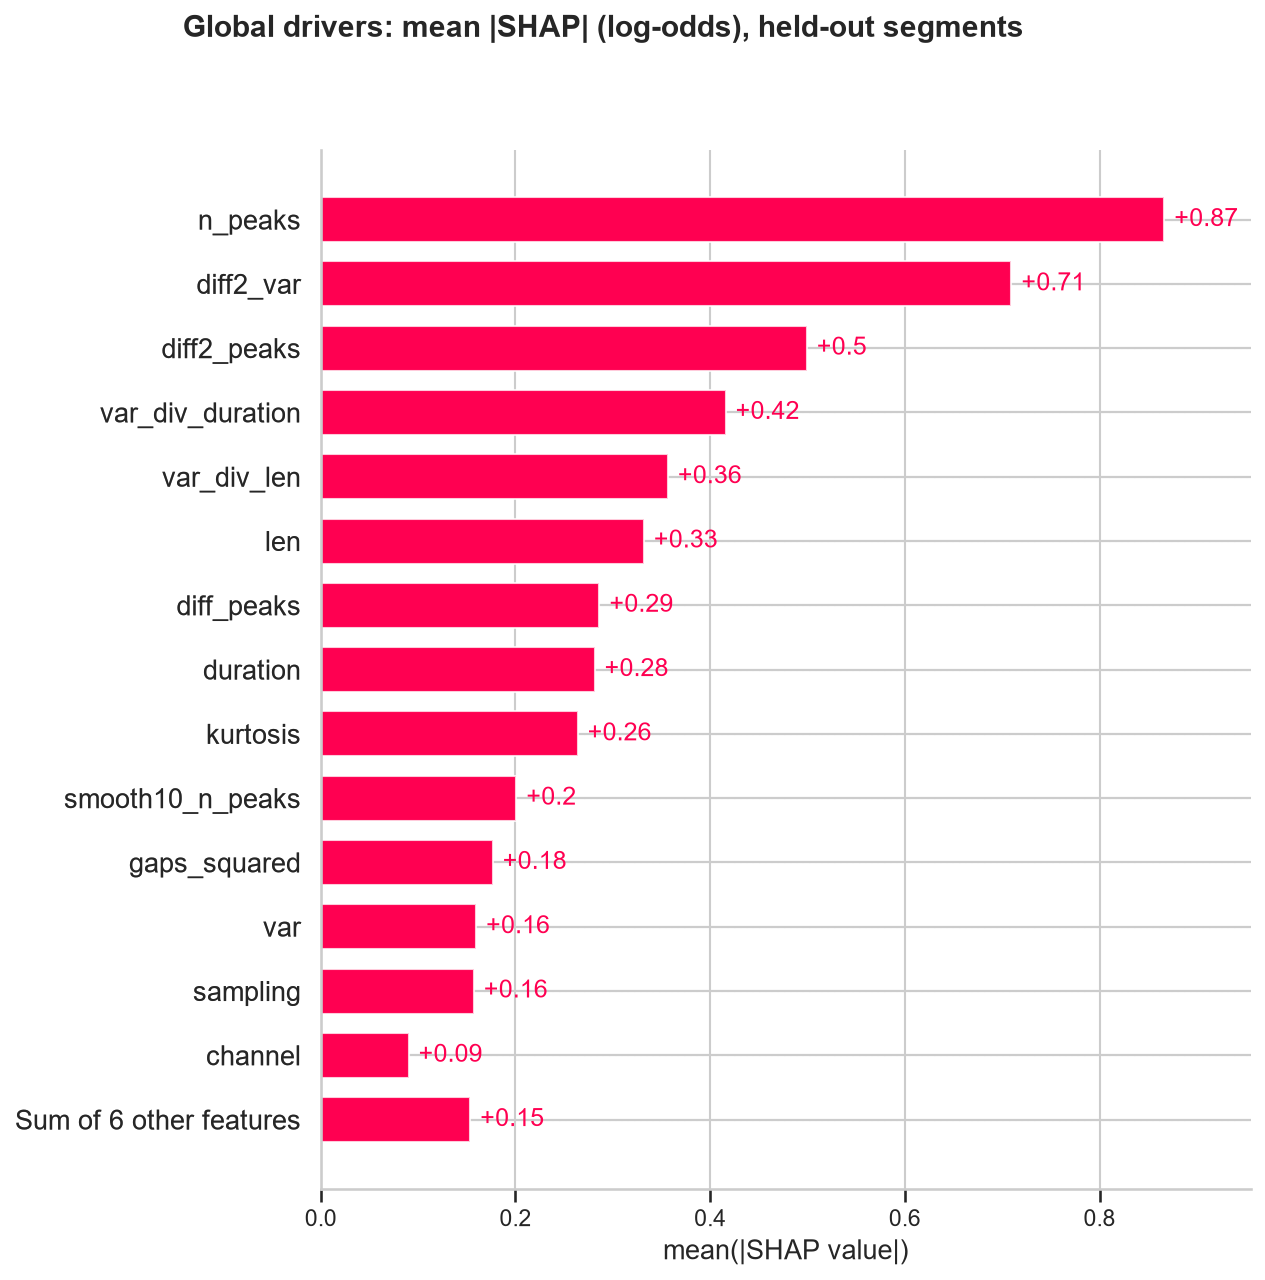

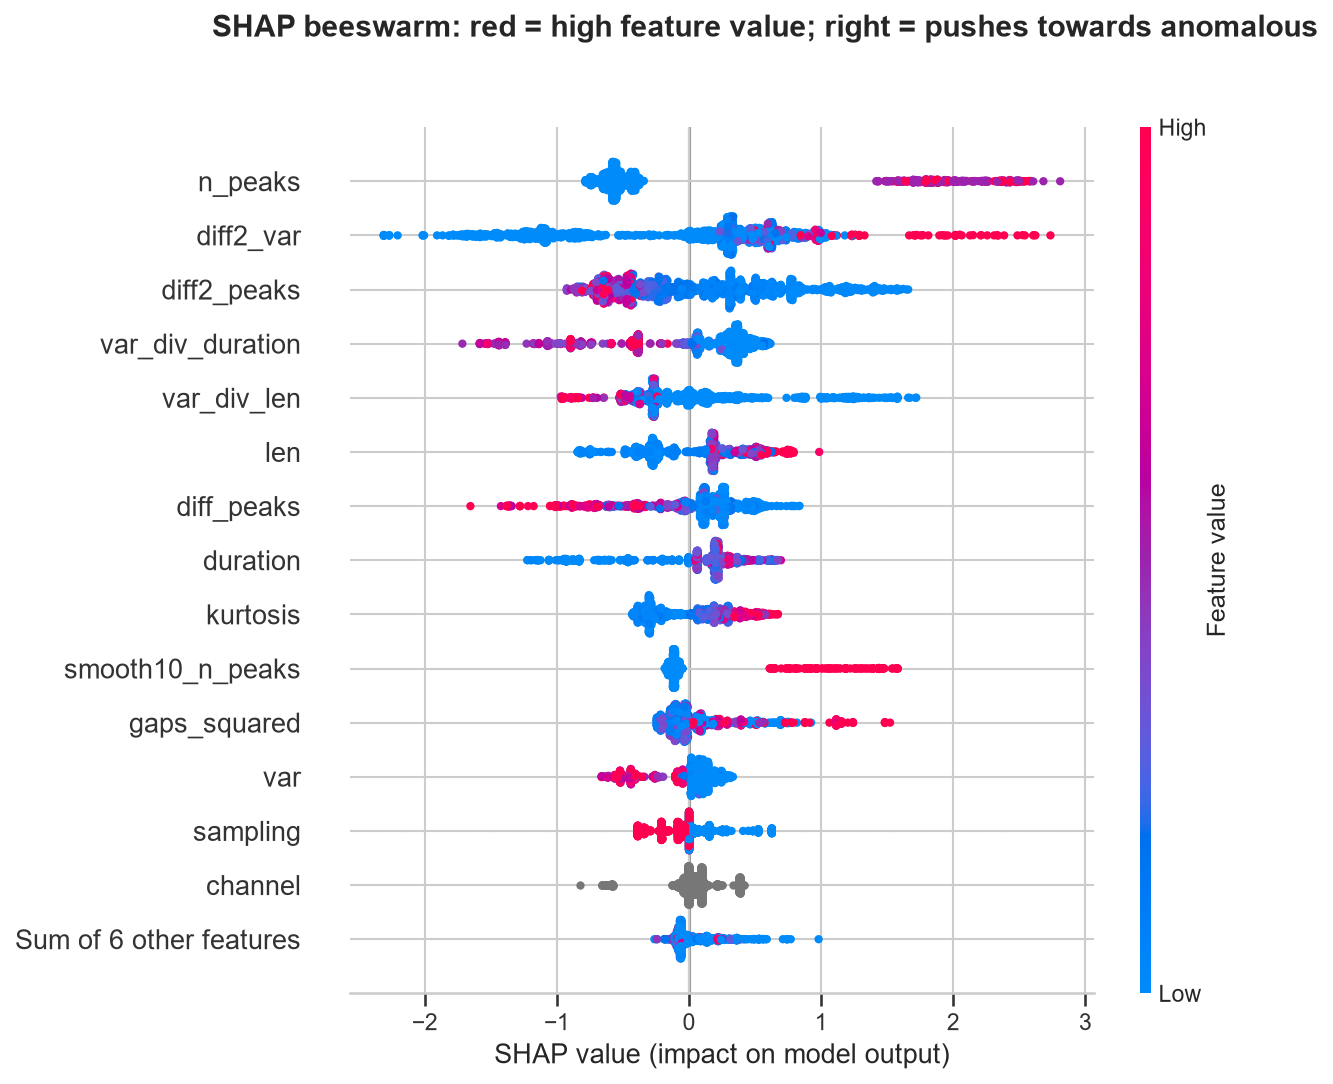

In [6]:
show("14_shap_global"); show("15_shap_beeswarm")

- **`n_peaks`** dominates: segments with more than one peak are pushed strongly towards *anomalous*. This matches the
  trace gallery (spikes, dropouts create extra peaks).
- **`diff2_var`** (variance of the second difference) is next: high curvature variance = sharp jumps and dropouts.
- **Channel contributes very little**, consistent with the channel-only baseline result — the model reads signal
  shape, not the channel identity.
- Features are correlated (EDA), so SHAP credit is shared between near-duplicates; rankings within correlated groups
  are not meaningful. SHAP describes *model association*, not physical causation.

## 5. Error analysis

In [7]:
oof = pd.read_csv(P["processed"] / "oof" / "hgb.csv")
thr = M["hgb"]["threshold_policy"]["threshold"]
oof["pred"] = (oof["score"] >= thr).astype(int)
oof["outcome"] = np.select(
    [oof.pred.eq(1) & oof.anomaly.eq(1), oof.pred.eq(1), oof.anomaly.eq(1)], ["TP", "FP", "FN"], "TN")
ct = pd.crosstab(oof["channel"], oof["outcome"])[["TP", "FN", "FP", "TN"]]
ct["recall"] = (ct.TP / (ct.TP + ct.FN)).round(2)
ct["precision"] = (ct.TP / (ct.TP + ct.FP)).round(2)
ct

outcome,TP,FN,FP,TN,recall,precision
channel,,,,,,
CADC0872,77,22,9,306,0.78,0.90
CADC0873,68,6,4,362,0.92,0.94
CADC0874,46,0,6,90,1.00,0.88
CADC0884,0,0,8,114,NaN,0.00
CADC0886,2,0,0,5,1.00,1.00
CADC0888,38,10,2,138,0.79,0.95
CADC0890,9,0,0,3,1.00,1.00
CADC0892,12,15,5,126,0.44,0.71
CADC0894,13,3,26,69,0.81,0.33


In [8]:
ds = pd.read_csv(P["raw"] / "dataset.csv").set_index("segment")
oof.join(ds[["len", "n_peaks", "kurtosis"]], on="segment").groupby("outcome")[["len", "n_peaks", "kurtosis", "score"]].median().round(3)

,len,n_peaks,kurtosis,score
outcome,,,,
FN,179.0,1.0,-1.160,0.152
FP,335.0,3.0,-1.150,0.630
TN,51.0,1.0,-1.361,0.027
TP,185.0,2.0,-1.016,0.962


- **Missed anomalies (FN)** are concentrated in CADC0872 and CADC0892 and typically have a **single peak** — subtle
  shape distortions that summary statistics do not capture well.
- **False alarms (FP)** are concentrated in CADC0894 and are **long, multi-peak normal segments**: peak counts grow with
  length, so the model confuses "long" with "spiky".
- CADC0884 has no anomalies at all, so its 8 false positives are pure review cost.

This motivates the Day-4 novelty models (which look for departure from *normal* behaviour rather than learning the
labelled patterns) and, if time allows, a raw-sequence model that sees shape directly.

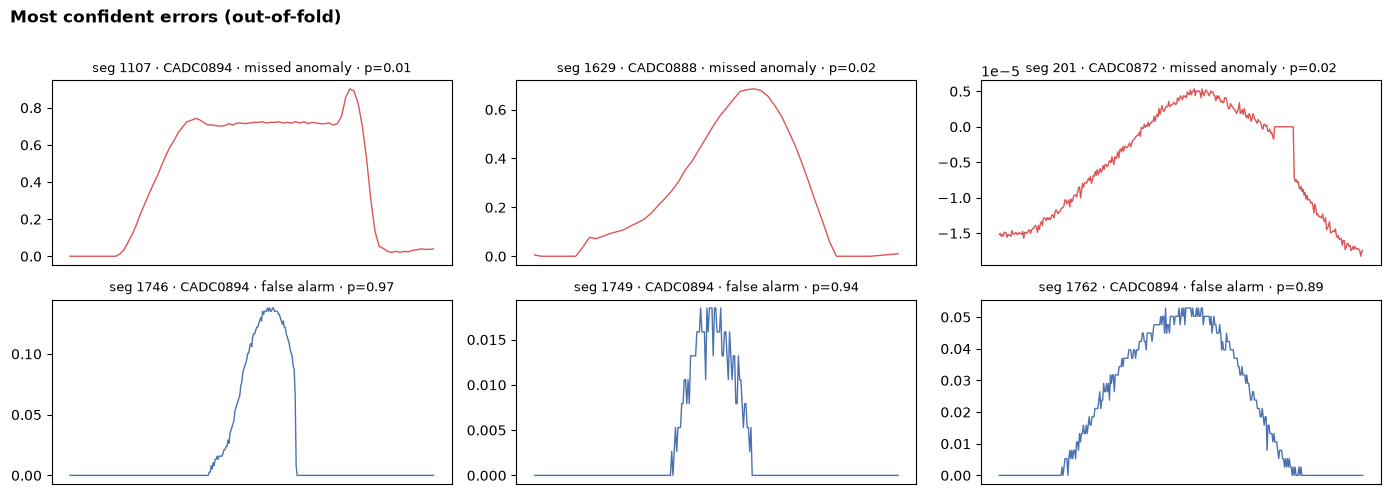

In [9]:
seg = pd.read_csv(P["raw"] / "segments.csv")
worst_fn = oof[oof.outcome.eq("FN")].nsmallest(3, "score")
worst_fp = oof[oof.outcome.eq("FP")].nlargest(3, "score")
fig, axes = plt.subplots(2, 3, figsize=(14, 5))
for row, (df_, tag, color) in enumerate([(worst_fn, "missed anomaly", "#DD5555"), (worst_fp, "false alarm", "#4C72B0")]):
    for ax, (_, r) in zip(axes[row], df_.iterrows()):
        t = seg[seg.segment == r.segment]["value"].to_numpy()
        ax.plot(t, color=color, lw=1)
        ax.set_title(f"seg {r.segment} · {r.channel} · {tag} · p={r.score:.2f}", fontsize=9)
        ax.set_xticks([])
fig.suptitle("Most confident errors (out-of-fold)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

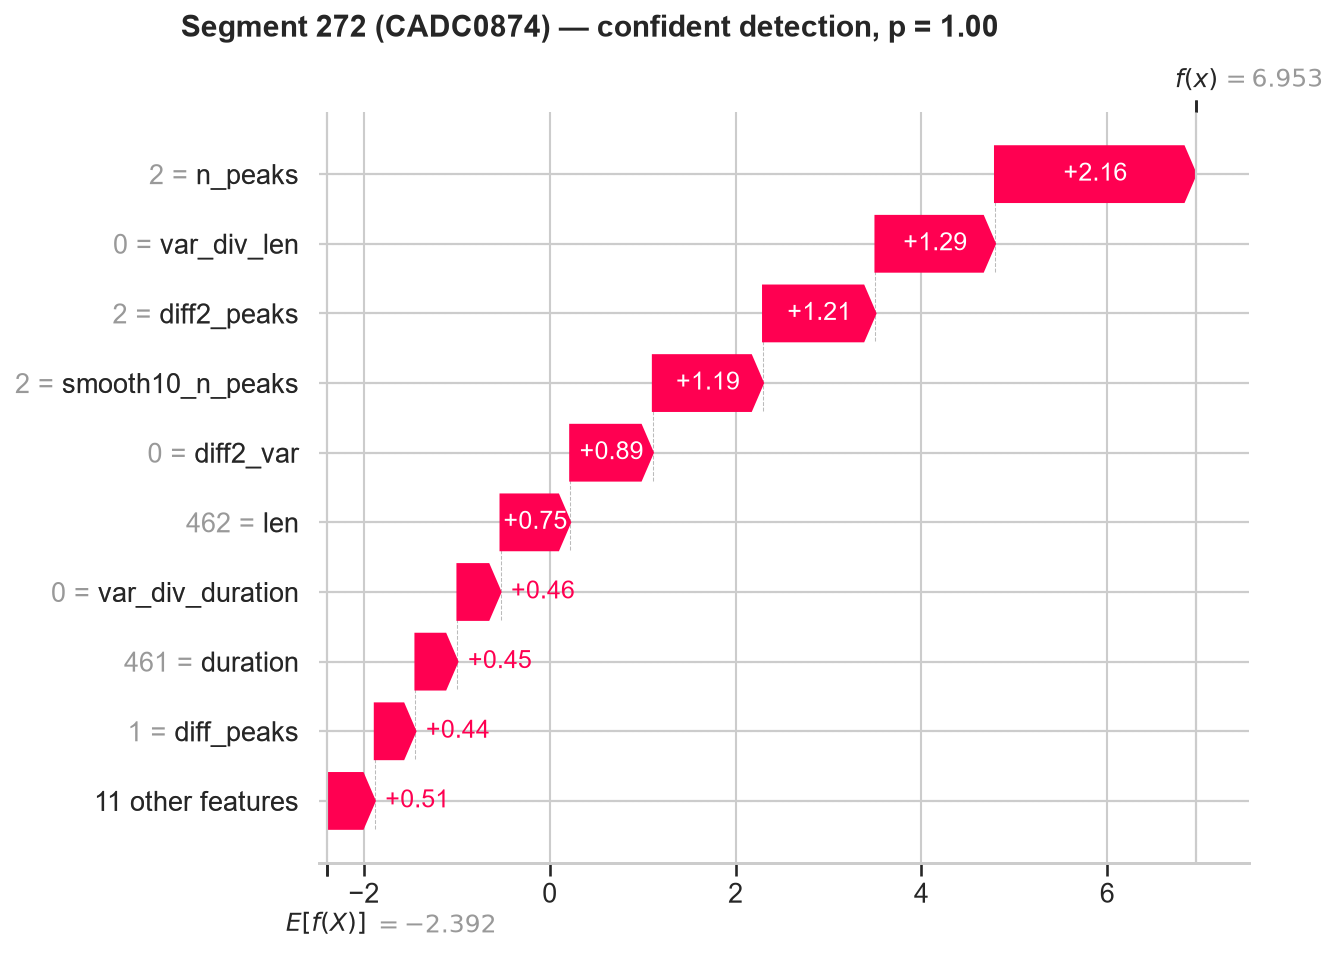

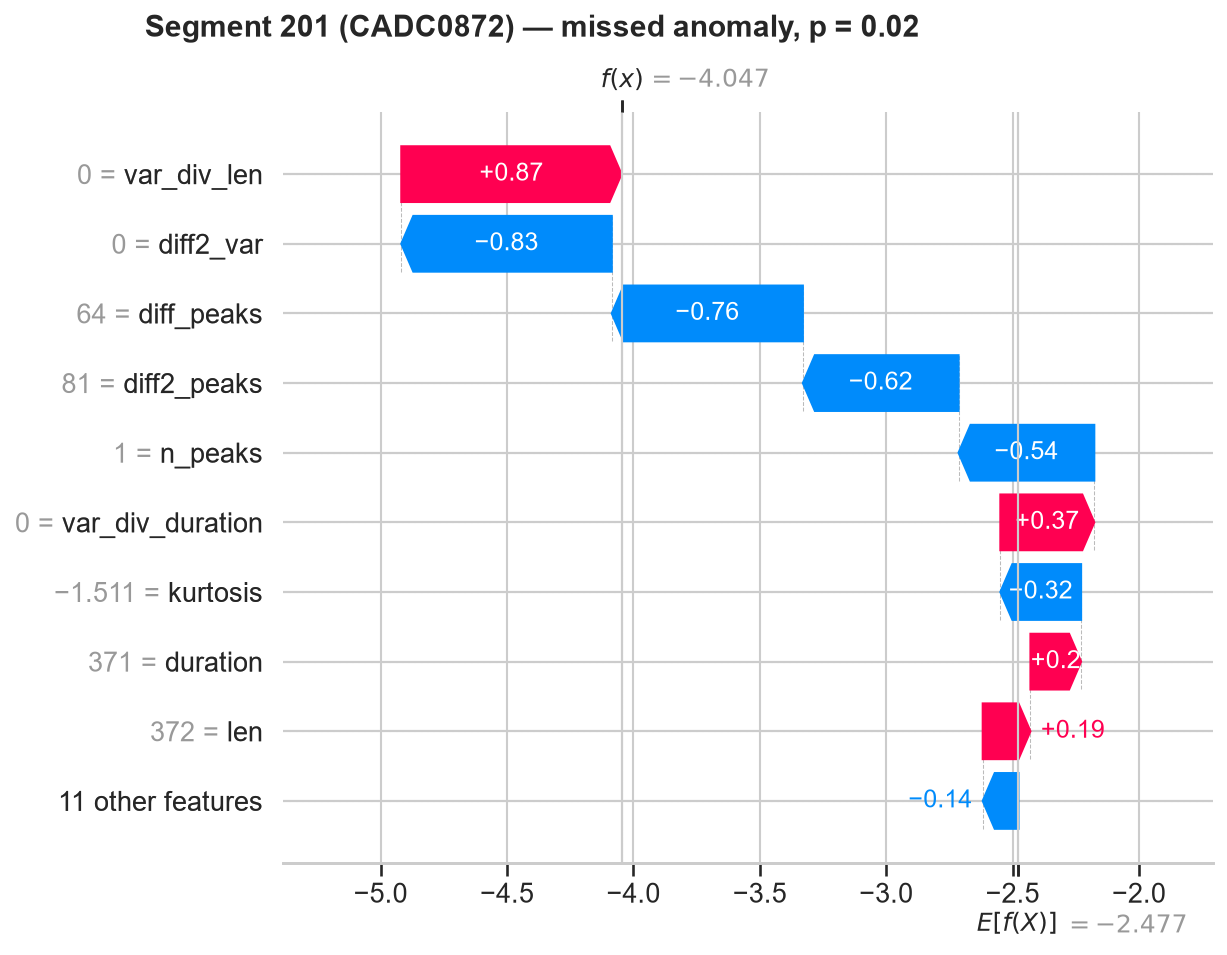

In [10]:
show("16_shap_waterfall_tp"); show("17_shap_waterfall_fn")

*Note: features such as `var_div_len` have magnitudes around 1e-9, so the waterfall's value labels round them to 0;
the SHAP contributions are unaffected.*

## Summary

| | |
|---|---|
| Model | HistGradientBoosting, 4 leaves, lr 0.03, 300 trees (one-SE rule) |
| Grouped-CV PR-AUC | **0.919 ± 0.060** (logistic 0.878 ± 0.078) |
| Significance | wins 11/15 folds; naive p = 0.03, **corrected p = 0.30** → not significant |
| Calibration | Brier 0.052 (logistic 0.060) |
| At the review threshold | precision 0.82 / recall 0.83 — same as logistic |
| Main drivers | n_peaks, diff2_var, diff2_peaks; channel negligible |
| Weak spots | subtle single-peak anomalies (CADC0872/0892); long multi-peak normals (CADC0894) |
| Decision | boosting = primary model, logistic = interpretable baseline; both go to the frozen test |